# BERT Fine-Tuning for IMDb Sentiment Classification

This notebook fine-tunes **BERT (`bert-base-uncased`)** for binary sentiment classification on the IMDb dataset using PyTorch.

**Labels**
- `0` = Negative
- `1` = Positive

**Experiment design**
- Training: 22,500 reviews
- Validation: 2,500 reviews
- Test: 25,000 reviews
- Maximum sequence length: 128
- Batch size: 8
- Optimizer: AdamW
- Learning rate: 2e-5

The validation set is used for model selection. The test set remains untouched until the final evaluation.

In [1]:
import torch
import torch.nn as nn

from datasets import load_dataset
from transformers import BertTokenizer, BertModel
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


/home/tseunzycode/machine-dl/tensorflow-env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.13.0+cu130
CUDA available: True
Device: cuda


## Load the BERT tokenizer

BERT uses WordPiece tokenization. The tokenizer adds special tokens such as `[CLS]` and `[SEP]`, converts tokens to BERT vocabulary IDs, and creates the attention mask and token-type IDs.


In [2]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

sentence = "This movie was absolutely fantastic"

encoded_example = tokenizer(
    sentence,
    padding="max_length",
    truncation=True,
    max_length=12,
    return_tensors="pt"
)

print("Tokens:")
print(tokenizer.convert_ids_to_tokens(encoded_example["input_ids"][0]))

print("\nInput IDs:")
print(encoded_example["input_ids"])

print("\nAttention mask:")
print(encoded_example["attention_mask"])

print("\nToken type IDs:")
print(encoded_example["token_type_ids"])


Tokens:
['[CLS]', 'this', 'movie', 'was', 'absolutely', 'fantastic', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']

Input IDs:
tensor([[  101,  2023,  3185,  2001,  7078, 10392,   102,     0,     0,     0,
             0,     0]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])

Token type IDs:
tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])


## Load and split the IMDb dataset

The original IMDb training set contains 25,000 labelled reviews. We split it into 90% training and 10% validation data. The original 25,000-review test set is preserved for final evaluation.


In [3]:
dataset = load_dataset("stanfordnlp/imdb")

split_dataset = dataset["train"].train_test_split(test_size=0.1, seed=42)

train_data = split_dataset["train"]
val_data = split_dataset["test"]
test_data = dataset["test"]

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))


Training: 22500
Validation: 2500
Test: 25000


In [4]:
train_data, val_data

(Dataset({
     features: ['text', 'label'],
     num_rows: 22500
 }),
 Dataset({
     features: ['text', 'label'],
     num_rows: 2500
 }))

## Create the PyTorch Dataset and DataLoaders

Each review is tokenized to a fixed length of 128 tokens. `squeeze(0)`  to remove the temporary single-example batch dimension created by the tokenizer; the DataLoader creates the real batch dimension later.


In [5]:
class IMDbDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        
        encoding = self.tokenizer(
            self.texts[idx],
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "token_type_ids": encoding["token_type_ids"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }


train_dataset = IMDbDataset(train_data["text"], train_data["label"], tokenizer)

val_dataset = IMDbDataset(val_data["text"], val_data["label"], tokenizer)

test_dataset = IMDbDataset(test_data["text"], test_data["label"], tokenizer)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 2813
Validation batches: 313
Test batches: 3125


## Building the BERT sentiment classifier

For each review, BERT produces a 768-dimensional contextual representation for every token. 


In [6]:
class BertSentimentClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.bert = BertModel.from_pretrained("bert-base-uncased")
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(768, 2)

    def forward(self, input_ids, attention_mask, token_type_ids):

        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )

        cls_output = outputs.last_hidden_state[:, 0, :]
        cls_output = self.dropout(cls_output)

        return self.classifier(cls_output)


model = BertSentimentClassifier().to(device)

total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1874.32it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total parameters: 109,483,778
Trainable parameters: 109,483,778


## Loss function and optimizer

`CrossEntropyLoss` works directly with the model's two raw logits. Softmax is therefore not applied before the loss.

AdamW uses a small learning rate because the pretrained BERT parameters are being fine-tuned rather than learned from scratch.


In [7]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)


## Training and validation functions

The training function performs forward propagation, loss calculation, backpropagation, and parameter updates.

The validation function uses `model.eval()` and `torch.no_grad()` because validation measures performance without updating model parameters.


In [8]:
def train_one_epoch(model, loader, optimizer, criterion, device, epoch):

    model.train()

    total_loss = 0
    total_correct = 0
    total_examples = 0

    progress_bar = tqdm(loader, desc=f"Epoch {epoch} Training")

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        token_type_ids = batch["token_type_ids"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        logits = model(
            input_ids=input_ids, 
            attention_mask=attention_mask, 
            token_type_ids=token_type_ids
        )

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(logits, dim=1)

        total_correct += (predictions == labels).sum().item()

        total_examples += labels.size(0)

        progress_bar.set_postfix(
            loss=f"{total_loss / (progress_bar.n + 1):.4f}",
            accuracy=f"{total_correct / total_examples:.4f}"
        )

    return (total_loss / len(loader), total_correct / total_examples )




def evaluate(model, loader, criterion, device, description="Validation"):

    model.eval()

    total_loss = 0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():

        for batch in tqdm(loader, desc=description):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            token_type_ids = batch["token_type_ids"].to(device)
            labels = batch["label"].to(device)

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )

            loss = criterion(logits, labels)

            total_loss += loss.item()

            predictions = torch.argmax(logits, dim=1)

            total_correct += (predictions == labels).sum().item()

            total_examples += labels.size(0)

    return (total_loss / len(loader), total_correct / total_examples)


## Fine-tune BERT and save the best checkpoint

The model is trained for three epochs. After each epoch, validation performance is measured.

The checkpoint with the **highest validation accuracy** is saved automatically. This avoids accidentally saving a later, overfitted model under the name of an earlier epoch.


In [12]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_epoch = 0
num_epochs = 3

for epoch in range(1, num_epochs + 1):

    train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer, criterion, device, epoch)

    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device, description=f"Epoch {epoch} Validation")

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch {epoch}")
    print(f"Training Loss:      {train_loss:.4f}")
    print(f"Training Accuracy:  {train_accuracy:.4f}")
    print(f"Validation Loss:    {val_loss:.4f}")
    print(f"Validation Accuracy:{val_accuracy:.4f}")

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch

        torch.save(model.state_dict(), "bert_imdb_best.pt")

        print("Best model checkpoint saved.")

print(
    f"\nBest epoch: {best_epoch} "
    f"(validation accuracy = {best_val_accuracy:.4f})")


Epoch 1 Validation: 100%|██████████| 313/313 [00:09<00:00, 31.99it/s] 



Epoch 1
Training Loss:      0.3354
Training Accuracy:  0.8508
Validation Loss:    0.2768
Validation Accuracy:0.8888
Best model checkpoint saved.


Epoch 2 Validation: 100%|██████████| 313/313 [00:12<00:00, 24.10it/s]



Epoch 2
Training Loss:      0.1832
Training Accuracy:  0.9281
Validation Loss:    0.3035
Validation Accuracy:0.8784


Epoch 3 Validation: 100%|██████████| 313/313 [00:12<00:00, 24.61it/s]


Epoch 3
Training Loss:      0.0854
Training Accuracy:  0.9699
Validation Loss:    0.3902
Validation Accuracy:0.8816

Best epoch: 1 (validation accuracy = 0.8888)


## Load the selected model for final testing

Run this after training. The test set should only be used after training and model selection are complete.


In [9]:
model.load_state_dict(
    torch.load("bert_imdb_best.pt", map_location=device)
)

model = model.to(device)
model.eval()

print("Best validation checkpoint restored.")


Best validation checkpoint restored.


## Final test evaluation

The next step is to evaluate the selected checkpoint on the untouched 25,000-review test set and calculate accuracy, precision, recall, F1 score, and the confusion matrix.


In [10]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Testing"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        token_type_ids = batch["token_type_ids"].to(device)
        labels = batch["label"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )

        predictions = torch.argmax(logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())

        all_labels.extend(labels.cpu().numpy())

Testing: 100%|██████████| 3125/3125 [01:50<00:00, 28.22it/s]


In [11]:
print("Number of predictions:", len(all_predictions))
print("Number of labels:", len(all_labels))

print("\nFirst 10 predictions:")
print(all_predictions[:10])

print("\nFirst 10 true labels:")
print(all_labels[:10])

Number of predictions: 25000
Number of labels: 25000

First 10 predictions:
[0, 1, 0, 1, 1, 0, 1, 0, 0, 0]

First 10 true labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[11033  1467]
 [ 1367 11133]]


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(all_labels, all_predictions)

recall = recall_score(all_labels, all_predictions)

f1 = f1_score(all_labels, all_predictions)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.8866
Precision: 0.8836
Recall:    0.8906
F1 Score:  0.8871


In [14]:
def predict_sentiment(text):

    encoding = tokenizer(
        text,
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)
    token_type_ids = encoding["token_type_ids"].to(device)

    model.eval()

    with torch.no_grad():

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        probabilities = torch.softmax(logits, dim=1)


    negative_prob = probabilities[0][0].item()
    positive_prob = probabilities[0][1].item()

    prediction = torch.argmax(probabilities, dim=1).item()

    sentiment = ("Positive" if prediction == 1 else "Negative")

    return sentiment, negative_prob, positive_prob

In [15]:
text = "This movie was absolutely fantastic."

sentiment, negative_prob, positive_prob = predict_sentiment(text)

print("Text:", text)
print("Prediction:", sentiment)
print(f"Negative probability: {negative_prob:.4f}")
print(f"Positive probability: {positive_prob:.4f}")

Text: This movie was absolutely fantastic.
Prediction: Positive
Negative probability: 0.0019
Positive probability: 0.9981


In [16]:
text = "This movie was not good."

sentiment, negative_prob, positive_prob = predict_sentiment(text)

print("Text:", text)
print("Prediction:", sentiment)
print(f"Negative probability: {negative_prob:.4f}")
print(f"Positive probability: {positive_prob:.4f}")

Text: This movie was not good.
Prediction: Negative
Negative probability: 0.9909
Positive probability: 0.0091


In [17]:
text = "This movie was terrible."

sentiment, negative_prob, positive_prob = predict_sentiment(text)

print("Text:", text)
print("Prediction:", sentiment)
print(f"Negative probability: {negative_prob:.4f}")
print(f"Positive probability: {positive_prob:.4f}")

Text: This movie was terrible.
Prediction: Negative
Negative probability: 0.9942
Positive probability: 0.0058


In [21]:
text = "This movie was not terrible, i don't hate it"

sentiment, negative_prob, positive_prob = predict_sentiment(text)

print("Text:", text)
print("Prediction:", sentiment)
print(f"Negative probability: {negative_prob:.4f}")
print(f"Positive probability: {positive_prob:.4f}")

Text: This movie was not terrible, i don't hate it
Prediction: Positive
Negative probability: 0.0686
Positive probability: 0.9314


In [ ]:
# text = "this movie was absolutely fantastic"
# text = "this movie was not absolutely terrible"
text = "this movie was absolutely terrible"

sentiment, negative_prob, positive_prob = predict_sentiment(text)

print("Text:", text)
print("Prediction:", sentiment)
print(f"Negative probability: {negative_prob:.4f}")
print(f"Positive probability: {positive_prob:.4f}")

Text: this movie was absolutely terrible
Prediction: Negative
Negative probability: 0.9964
Positive probability: 0.0036


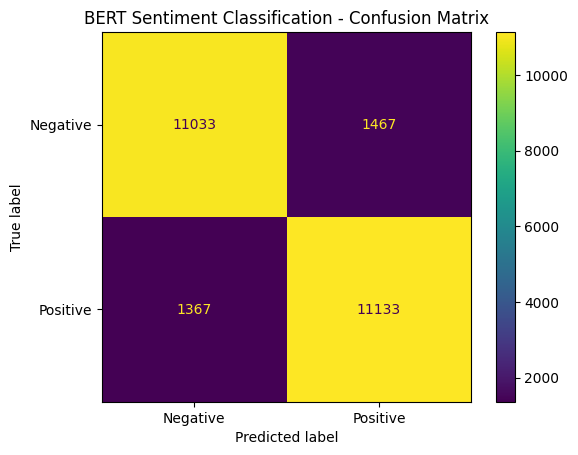

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()

plt.title("BERT Sentiment Classification - Confusion Matrix")
plt.show()

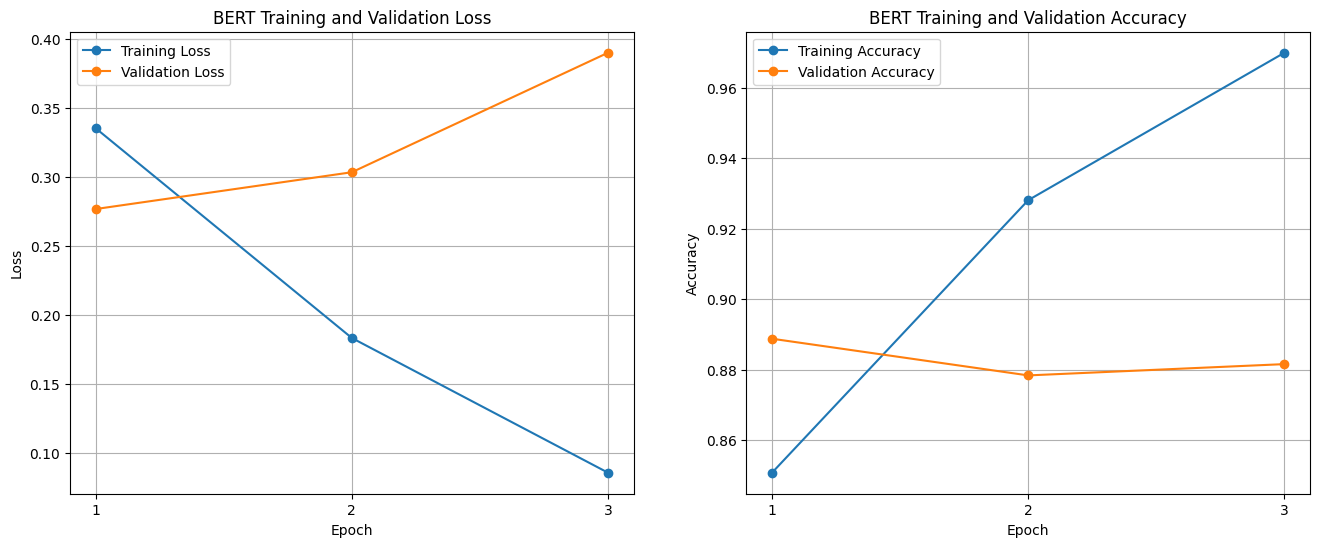

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

epochs = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training Loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("BERT Training and Validation Loss")
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(True)


axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("BERT Training and Validation Accuracy")
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(True)

